## Time-Series Data -- Advanced Machine Learning

**Purpose:** apply RNNs to the weather time-series forecasting problem
, and improve the performance of
the network using different methods:
  1. Adjusting the number of units in each recurrent layer in the
     stacked setup
  2. Using LSTM instead of GRU
  3. Using a combination of 1D convnets and an RNN

The best-performing models (in terms of validation MAE) are then run
on the test set.

In [1]:
# ---------------------------------------------------------------------
# Download and unpack the Jena weather dataset
# ---------------------------------------------------------------------
!wget https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip
!unzip -o jena_climate_2009_2016.csv.zip

--2026-11-09 06:22:53--  https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip
Resolving s3.amazonaws.com (s3.amazonaws.com)... 16.15.199.3, 16.15.212.132, 52.217.174.104, ...
Connecting to s3.amazonaws.com (s3.amazonaws.com)|16.15.199.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13565642 (13M) [application/zip]
Saving to: ‘jena_climate_2009_2016.csv.zip’

jena_climate_2009_2 100%[===================>]  12.94M  20.7MB/s    in 0.6s    

2026-11-09 06:22:54 (20.7 MB/s) - ‘jena_climate_2009_2016.csv.zip’ saved [13565642/13565642]

Archive:  jena_climate_2009_2016.csv.zip
  inflating: jena_climate_2009_2016.csv  
  inflating: __MACOSX/._jena_climate_2009_2016.csv  


In [2]:
# ---------------------------------------------------------------------
# Setup — import and run settings
# ---------------------------------------------------------------------
import json
import os
import time
import numpy as np
from matplotlib import pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
EPOCHS = 10

print(os.path.exists("results.json"), os.path.exists("jena_climate_2009_2016.csv"))


False True


In [3]:
# ---------------------------------------------------------------------
# Setup — folders and results file
# ---------------------------------------------------------------------
FIGURE_DIR = "figures"
CHECKPOINT_DIR = "checkpoints"
RESULTS_PATH = "results.json"
os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

In [4]:
# ---------------------------------------------------------------------
# Setup — results helpers
# ---------------------------------------------------------------------
def load_results():
    if os.path.exists(RESULTS_PATH):
        with open(RESULTS_PATH) as f:
            return json.load(f)
    return {}

def save_results(results):
    with open(RESULTS_PATH, "w") as f:
        json.dump(results, f, indent=2)

In [5]:
# ---------------------------------------------------------------------
# Names the file
# ---------------------------------------------------------------------
fname = os.path.join("jena_climate_2009_2016.csv")

with open(fname) as f:
    data = f.read()

lines = data.split("\n")
header = lines[0].split(",")
lines = lines[1:]
lines = [line for line in lines if line.strip()]  # drop any blank line

In [6]:
# ---------------------------------------------------------------------
# Parse the data
# ---------------------------------------------------------------------
temperature = np.zeros((len(lines),))
raw_data = np.zeros((len(lines), len(header) - 1))
for i, line in enumerate(lines):
    values = [float(x) for x in line.split(",")[1:]]
    temperature[i] = values[1]
    raw_data[i, :] = values[:]

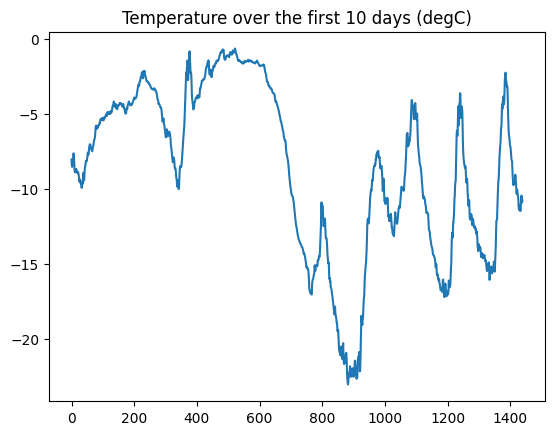

In [8]:
# ---------------------------------------------------------------------
# Plot the temperature timeseries (first 10 days)
# ---------------------------------------------------------------------
plt.figure()
plt.plot(range(1440), temperature[:1440])
plt.title("Temperature over the first 10 days (degC)")
plt.show()

In [9]:

# ---------------------------------------------------------------------
# Compute the number of samples to use for each data split
# ---------------------------------------------------------------------
num_train_samples = int(0.5 * len(raw_data))
num_val_samples = int(0.25 * len(raw_data))
num_test_samples = len(raw_data) - num_train_samples - num_val_samples
print("num_train_samples:", num_train_samples)
print("num_val_samples:", num_val_samples)
print("num_test_samples:", num_test_samples)

num_train_samples: 210225
num_val_samples: 105112
num_test_samples: 105114


In [10]:
# ---------------------------------------------------------------------
# Preparing the data: normalizing the data
# (normalization statistics are computed on the training data only)
# ---------------------------------------------------------------------
mean = raw_data[:num_train_samples].mean(axis=0)
raw_data -= mean
std = raw_data[:num_train_samples].std(axis=0)
raw_data /= std

In [11]:
# ---------------------------------------------------------------------
# Instantiating datasets for training, validation, and testing
# ---------------------------------------------------------------------
sampling_rate = 6
sequence_length = 120
delay = sampling_rate * (sequence_length + 24 - 1)
batch_size = 256

In [12]:
train_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=temperature[delay:],
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=0,
    end_index=num_train_samples)

In [13]:
val_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=temperature[delay:],
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=num_train_samples,
    end_index=num_train_samples + num_val_samples)

In [14]:
test_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=temperature[delay:],
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=num_train_samples + num_val_samples)

In [16]:
for samples, targets in train_dataset:
    print("samples shape:", samples.shape)
    print("targets shape:", targets.shape)
    break

results = load_results()

samples shape: (256, 120, 14)
targets shape: (256,)


In [17]:
# ---------------------------------------------------------------------
# Common-sense baseline
# (predict that the temperature 24 hours from now will be the same as
#  the current temperature)
# ---------------------------------------------------------------------
def evaluate_naive_method(dataset):
    total_abs_err = 0.
    samples_seen = 0
    for samples, targets in dataset:
        preds = samples[:, -1, 1] * std[1] + mean[1]
        total_abs_err += np.sum(np.abs(preds - targets))
        samples_seen += samples.shape[0]
    return total_abs_err / samples_seen

In [18]:
naive_val = float(evaluate_naive_method(val_dataset))
naive_test = float(evaluate_naive_method(test_dataset))
print(f"Validation MAE: {naive_val:.2f}")
print(f"Test MAE: {naive_test:.2f}")
results["naive"] = {
    "label": "Common-sense baseline (no learning)",
    "val_mae": naive_val,
    "test_mae": naive_test,
}
save_results(results)


Validation MAE: 2.44
Test MAE: 2.62


In [19]:
# ---------------------------------------------------------------------
# Trains and tests every model.
# ---------------------------------------------------------------------
def train_and_evaluate(key, label, model):
    checkpoint_path = os.path.join(CHECKPOINT_DIR, f"jena_{key}.keras")
    callbacks = [
        keras.callbacks.ModelCheckpoint(checkpoint_path,
                                        monitor="val_mae",
                                        mode="min",
                                        save_best_only=True)
    ]
    model.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
    model.summary()
    start = time.time()
    history = model.fit(train_dataset,
                        epochs=EPOCHS,
                        validation_data=val_dataset,
                        callbacks=callbacks,
                        verbose=2)
    seconds = time.time() - start
    best_val_mae = float(min(history.history["val_mae"]))
    best_epoch = int(np.argmin(history.history["val_mae"])) + 1
    model = keras.models.load_model(checkpoint_path)
    test_mae = float(model.evaluate(test_dataset, verbose=0)[1])
    print(f"{label} -- best validation MAE: {best_val_mae:.2f} "
          f"(epoch {best_epoch})")
    print(f"Test MAE: {test_mae:.2f}")
    with open(f"history_{key}.json", "w") as f:
        json.dump({"mae": [float(x) for x in history.history["mae"]],
                   "val_mae": [float(x) for x in history.history["val_mae"]]},
                  f, indent=2)
    results[key] = {
        "label": label,
        "val_mae": best_val_mae,
        "test_mae": test_mae,
        "best_epoch": best_epoch,
        "epochs_run": len(history.history["val_mae"]),
        "train_seconds": seconds,
    }
    save_results(results)
    return results[key]

In [20]:
# ---------------------------------------------------------------------
# Model 1 — Stacked GRU (32 → 32)
# ---------------------------------------------------------------------
inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))
x = layers.GRU(32, return_sequences=True)(inputs)
x = layers.GRU(32)(x)
outputs = layers.Dense(1)(x)
model = keras.Model(inputs, outputs)
train_and_evaluate("gru", "Stacked GRU (32 -> 32)", model)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 120, 32)        │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,977 (42.88 KB)

 Trainable params: 10,977 (42.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 62s - 76ms/step - loss: 18.4430 - mae: 3.0949 - val_loss: 9.2839 - val_mae: 2.3620
Epoch 2/10
819/819 - 61s - 74ms/step - loss: 8.8462 - mae: 2.3208 - val_loss: 8.8441 - val_mae: 2.3184
Epoch 3/10
819/819 - 58s - 71ms/step - loss: 7.9593 - mae: 2.2109 - val_loss: 10.0839 - val_mae: 2.4682
Epoch 4/10
819/819 - 60s - 73ms/step - loss: 7.1680 - mae: 2.1038 - val_loss: 10.1217 - val_mae: 2.4862
Epoch 5/10
819/819 - 59s - 72ms/step - loss: 6.4259 - mae: 1.9969 - val_loss: 10.5380 - val_mae: 2.5411
Epoch 6/10
819/819 - 59s - 72ms/step - loss: 5.7430 - mae: 1.8866 - val_loss: 10.9339 - val_mae: 2.5845
Epoch 7/10
819/819 - 59s - 72ms/step - loss: 5.1233 - mae: 1.7784 - val_loss: 11.0919 - val_mae: 2.6010
Epoch 8/10
819/819 - 60s - 73ms/step - loss: 4.5504 - mae: 1.6718 - val_loss: 11.7753 - val_mae: 2.6773
Epoch 9/10
819/819 - 59s - 72ms/step - loss: 4.0448 - mae: 1.5739 - val_loss: 13.1803 - val_mae: 2.8443
Epoch 10/10
819/819 - 59s - 73ms/step - loss: 3.6438 - mae: 1.490

{'label': 'Stacked GRU (32 -> 32)',
 'val_mae': 2.318415403366089,
 'test_mae': 2.4913856983184814,
 'best_epoch': 2,
 'epochs_run': 10,
 'train_seconds': 595.5510773658752}

In [21]:
# ---------------------------------------------------------------------
#  Model 2 — Stacked GRU (64 → 32), units adjusted
# ---------------------------------------------------------------------
inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))
x = layers.GRU(64, return_sequences=True)(inputs)
x = layers.GRU(32)(x)
outputs = layers.Dense(1)(x)
model = keras.Model(inputs, outputs)
train_and_evaluate("gru_units", "Stacked GRU (64 -> 32)", model)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 120, 64)        │        15,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,801 (96.88 KB)

 Trainable params: 24,801 (96.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 59s - 72ms/step - loss: 18.3440 - mae: 3.0959 - val_loss: 8.7914 - val_mae: 2.3066
Epoch 2/10
819/819 - 64s - 78ms/step - loss: 8.3793 - mae: 2.2664 - val_loss: 9.3963 - val_mae: 2.3873
Epoch 3/10
819/819 - 63s - 77ms/step - loss: 6.8232 - mae: 2.0493 - val_loss: 10.4392 - val_mae: 2.4951
Epoch 4/10
819/819 - 55s - 67ms/step - loss: 5.2647 - mae: 1.7996 - val_loss: 11.6357 - val_mae: 2.6324
Epoch 5/10
819/819 - 56s - 68ms/step - loss: 3.9572 - mae: 1.5581 - val_loss: 12.4263 - val_mae: 2.7353
Epoch 6/10
819/819 - 63s - 77ms/step - loss: 3.0673 - mae: 1.3698 - val_loss: 13.2752 - val_mae: 2.8323
Epoch 7/10
819/819 - 83s - 101ms/step - loss: 2.5390 - mae: 1.2427 - val_loss: 13.9060 - val_mae: 2.8998
Epoch 8/10
819/819 - 82s - 100ms/step - loss: 2.1527 - mae: 1.1417 - val_loss: 13.8154 - val_mae: 2.8857
Epoch 9/10
819/819 - 63s - 77ms/step - loss: 1.8775 - mae: 1.0656 - val_loss: 14.1169 - val_mae: 2.9164
Epoch 10/10
819/819 - 62s - 76ms/step - loss: 1.6679 - mae: 1.0

{'label': 'Stacked GRU (64 -> 32)',
 'val_mae': 2.306551694869995,
 'test_mae': 2.470705270767212,
 'best_epoch': 1,
 'epochs_run': 10,
 'train_seconds': 649.2527446746826}

In [22]:
# ---------------------------------------------------------------------
#  Model 3 — Stacked LSTM (32 → 32)
# ---------------------------------------------------------------------
inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))
x = layers.LSTM(32, return_sequences=True)(inputs)
x = layers.LSTM(32)(x)
outputs = layers.Dense(1)(x)
model = keras.Model(inputs, outputs)
train_and_evaluate("lstm", "Stacked LSTM (32 -> 32)", model)

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 120, 32)        │         6,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,369 (56.13 KB)

 Trainable params: 14,369 (56.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 63s - 77ms/step - loss: 19.9028 - mae: 3.2136 - val_loss: 9.9752 - val_mae: 2.4716
Epoch 2/10
819/819 - 64s - 78ms/step - loss: 7.8319 - mae: 2.1833 - val_loss: 10.8615 - val_mae: 2.5798
Epoch 3/10
819/819 - 60s - 73ms/step - loss: 6.1901 - mae: 1.9364 - val_loss: 11.7931 - val_mae: 2.6976
Epoch 4/10
819/819 - 60s - 74ms/step - loss: 5.0253 - mae: 1.7403 - val_loss: 12.9388 - val_mae: 2.8197
Epoch 5/10
819/819 - 61s - 75ms/step - loss: 4.2084 - mae: 1.5899 - val_loss: 12.7761 - val_mae: 2.8096
Epoch 6/10
819/819 - 62s - 76ms/step - loss: 3.6296 - mae: 1.4725 - val_loss: 13.9327 - val_mae: 2.9334
Epoch 7/10
819/819 - 61s - 74ms/step - loss: 3.1754 - mae: 1.3759 - val_loss: 14.3641 - val_mae: 2.9712
Epoch 8/10
819/819 - 83s - 101ms/step - loss: 2.8342 - mae: 1.2977 - val_loss: 14.6934 - val_mae: 3.0283
Epoch 9/10
819/819 - 63s - 78ms/step - loss: 2.5960 - mae: 1.2406 - val_loss: 14.0016 - val_mae: 2.9353
Epoch 10/10
819/819 - 61s - 75ms/step - loss: 2.3977 - mae: 1.1

{'label': 'Stacked LSTM (32 -> 32)',
 'val_mae': 2.471649646759033,
 'test_mae': 2.56708025932312,
 'best_epoch': 1,
 'epochs_run': 10,
 'train_seconds': 639.3027966022491}

In [23]:
# ---------------------------------------------------------------------
#  Model 4 — 1D convnet + GRU
# ---------------------------------------------------------------------
inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))
x = layers.Conv1D(8, 24, activation="relu")(inputs)
x = layers.MaxPooling1D(2)(x)
x = layers.Conv1D(8, 12, activation="relu")(x)
x = layers.MaxPooling1D(2)(x)
x = layers.Conv1D(8, 6, activation="relu")(x)
x = layers.GRU(32)(x)
outputs = layers.Dense(1)(x)
model = keras.Model(inputs, outputs)
train_and_evaluate("conv_gru", "1D convnet + GRU", model)

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 97, 8)          │         2,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 48, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 37, 8)          │           776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 18, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 13, 8)          │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_4 (GRU)                     │ (None, 32)             │         4,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,929 (30.97 KB)

 Trainable params: 7,929 (30.97 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 53s - 65ms/step - loss: 24.2730 - mae: 3.6213 - val_loss: 12.1741 - val_mae: 2.7323
Epoch 2/10
819/819 - 49s - 59ms/step - loss: 11.3421 - mae: 2.6501 - val_loss: 11.8962 - val_mae: 2.7128
Epoch 3/10
819/819 - 49s - 59ms/step - loss: 10.2872 - mae: 2.5242 - val_loss: 12.3993 - val_mae: 2.7857
Epoch 4/10
819/819 - 48s - 58ms/step - loss: 9.5204 - mae: 2.4255 - val_loss: 12.4415 - val_mae: 2.7953
Epoch 5/10
819/819 - 49s - 60ms/step - loss: 8.8312 - mae: 2.3336 - val_loss: 12.7501 - val_mae: 2.8359
Epoch 6/10
819/819 - 49s - 60ms/step - loss: 8.1603 - mae: 2.2388 - val_loss: 13.6874 - val_mae: 2.9277
Epoch 7/10
819/819 - 54s - 66ms/step - loss: 7.6335 - mae: 2.1616 - val_loss: 14.2065 - val_mae: 2.9729
Epoch 8/10
819/819 - 76s - 93ms/step - loss: 7.1764 - mae: 2.0918 - val_loss: 13.7996 - val_mae: 2.9377
Epoch 9/10
819/819 - 49s - 60ms/step - loss: 6.7760 - mae: 2.0271 - val_loss: 13.5521 - val_mae: 2.9092
Epoch 10/10
819/819 - 49s - 59ms/step - loss: 6.4439 - mae: 1

{'label': '1D convnet + GRU',
 'val_mae': 2.7127716541290283,
 'test_mae': 2.8232920169830322,
 'best_epoch': 2,
 'epochs_run': 10,
 'train_seconds': 524.6207160949707}


Summary of results (MAE in degC)
Model                                       Val MAE Test MAE
Common-sense baseline (no learning)            2.44     2.62
Stacked GRU (32 -> 32)                         2.32     2.49
Stacked GRU (64 -> 32)                         2.31     2.47
Stacked LSTM (32 -> 32)                        2.47     2.57
1D convnet + GRU                               2.71     2.82


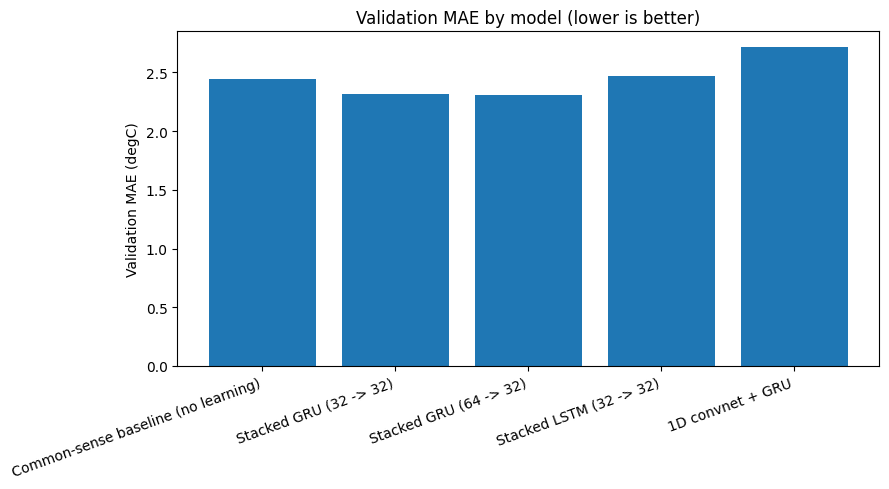

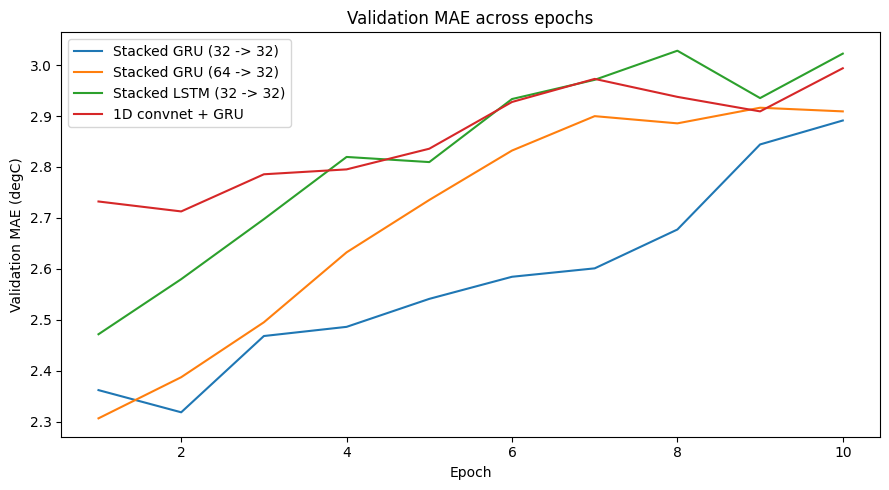


Best model by validation MAE: Stacked GRU (64 -> 32) (val MAE 2.31, test MAE 2.47)
That is a 5.5% improvement over the common-sense baseline (val MAE 2.44).


In [24]:
# ---------------------------------------------------------------------
#  Summary — results table, graphs, and the best model
# ---------------------------------------------------------------------
results = load_results()
order = ["naive", "gru", "gru_units", "lstm", "conv_gru"]
rows = [(key, results[key]) for key in order if key in results]
rows_by_val = sorted(rows, key=lambda kv: kv[1]["val_mae"])

print("\nSummary of results (MAE in degC)")
print(f"{'Model':42s} {'Val MAE':>8s} {'Test MAE':>8s}")
for key, r in rows:
    print(f"{r['label']:42s} {r['val_mae']:8.2f} {r['test_mae']:8.2f}")

with open("results_summary.csv", "w") as f:
    f.write("Model,Validation MAE,Test MAE\n")
    for key, r in rows:
        f.write(f"{r['label']},{r['val_mae']:.4f},{r['test_mae']:.4f}\n")

# Summary graph: validation MAE by model
labels = [r["label"] for key, r in rows]
val_maes = [r["val_mae"] for key, r in rows]
plt.figure(figsize=(9, 5))
plt.bar(range(len(labels)), val_maes)
plt.xticks(range(len(labels)), labels, rotation=20, ha="right")
plt.ylabel("Validation MAE (degC)")
plt.title("Validation MAE by model (lower is better)")
plt.tight_layout()
plt.show()

# Training curves: validation MAE across epochs for the learned models
plt.figure(figsize=(9, 5))
for key, r in rows:
    hist_path = f"history_{key}.json"
    if os.path.exists(hist_path):
        with open(hist_path) as f:
            hist = json.load(f)
        epochs = range(1, len(hist["val_mae"]) + 1)
        plt.plot(epochs, hist["val_mae"], label=r["label"])
plt.xlabel("Epoch")
plt.ylabel("Validation MAE (degC)")
plt.title("Validation MAE across epochs")
plt.legend()
plt.tight_layout()
plt.show()

best_key, best = rows_by_val[0]
naive = results["naive"]
improvement = 100.0 * (naive["val_mae"] - best["val_mae"]) / naive["val_mae"]
print(f"\nBest model by validation MAE: {best['label']} "
      f"(val MAE {best['val_mae']:.2f}, test MAE {best['test_mae']:.2f})")
print(f"That is a {improvement:.1f}% improvement over the common-sense "
      f"baseline (val MAE {naive['val_mae']:.2f}).")